In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Library berhasil diimpor.")


Library berhasil diimpor.


In [2]:
file_path = "original.csv"

if not os.path.exists(file_path):
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = next(iter(uploaded))
    except Exception:
        raise FileNotFoundError(
            "File original.csv tidak ditemukan. Letakkan original.csv satu folder "
            "dengan notebook, lalu jalankan ulang sel ini."
        )

df_raw = pd.read_csv(file_path)
print("Dataset berhasil dibaca.")
print("Dimensi awal:", df_raw.shape)
display(df_raw.head())

Dataset berhasil dibaca.
Dimensi awal: (87, 22)


,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,TUNDRA LSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Percent Attended,"label (fail=1, pass=0)",Unnamed: 20,Unnamed: 21
0,0.0,38.0,5.0,5.0,4.0,5.0,4.0,4.0,5.0,5.0,0.0,1.0,13.333806,19.0,7.41,0.620767,3.0,9.0,25.000000,1.0,NaN,NaN
1,0.0,22.0,4.0,2.0,1.0,3.0,4.0,4.0,4.0,5.0,0.0,1.0,15.844126,1.0,0.03,0.002513,0.0,12.0,0.000000,1.0,NaN,NaN
2,0.0,21.0,4.0,5.0,4.0,5.0,4.0,4.0,5.0,5.0,0.0,1.0,17.706573,25.0,6.14,0.514374,5.0,7.0,41.666667,1.0,NaN,NaN
3,0.0,25.0,5.0,4.0,3.0,4.0,3.0,3.0,5.0,5.0,0.0,0.0,17.327498,3.0,0.16,0.013404,0.0,12.0,0.000000,1.0,NaN,NaN
4,0.0,20.0,5.0,4.0,3.0,4.0,3.0,3.0,4.0,4.0,0.0,1.0,0.000000,25.0,4.03,0.337610,11.0,1.0,91.666667,1.0,NaN,NaN


In [3]:
print("Informasi tipe data:")
df_raw.info()

print("\\nJumlah nilai hilang per kolom:")
display(df_raw.isna().sum().to_frame("Jumlah Missing Value"))

print("\\nStatistik deskriptif:")
display(df_raw.describe().T)

Informasi tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             80 non-null     float64
 1   Age                                80 non-null     float64
 2   POLAR4 Quintile                    80 non-null     float64
 3   POLAR3 Quintile                    80 non-null     float64
 4   Adult HE 2001 Quintile             80 non-null     float64
 5   Adult HE 2011 Quintile             80 non-null     float64
 6   TUNDRA MSOA Quintile               80 non-null     float64
 7   TUNDRA LSOA Quintile               80 non-null     float64
 8   Gaps GCSE Quintile                 80 non-null     float64
 9   Gaps GCSE Ethnicity Quintile       80 non-null     float64
 10  Uni Connect target ward            80 non-null     float64
 11  attending from home?               80 non-null    

,Jumlah Missing Value
Gender,7
Age,7
POLAR4 Quintile,7
POLAR3 Quintile,7
Adult HE 2001 Quintile,7
Adult HE 2011 Quintile,7
TUNDRA MSOA Quintile,7
TUNDRA LSOA Quintile,7
Gaps GCSE Quintile,7
Gaps GCSE Ethnicity Quintile,7


\nStatistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
Gender,80.0,0.125000,0.332805,0.000000,0.000000,0.000000,0.000000,1.000000
Age,80.0,22.212500,4.451408,19.000000,20.000000,21.000000,22.000000,44.000000
POLAR4 Quintile,80.0,3.575000,1.438837,1.000000,2.000000,4.000000,5.000000,5.000000
POLAR3 Quintile,80.0,3.287500,1.433715,1.000000,2.000000,4.000000,4.250000,5.000000
Adult HE 2001 Quintile,80.0,2.712500,1.203305,1.000000,2.000000,3.000000,4.000000,5.000000
Adult HE 2011 Quintile,80.0,3.275000,1.395971,0.000000,2.000000,4.000000,4.000000,5.000000
TUNDRA MSOA Quintile,80.0,2.850000,1.293606,0.000000,2.000000,3.000000,4.000000,5.000000
TUNDRA LSOA Quintile,80.0,2.850000,1.293606,0.000000,2.000000,3.000000,4.000000,5.000000
Gaps GCSE Quintile,80.0,3.650000,1.543463,0.000000,3.000000,4.000000,5.000000,5.000000
Gaps GCSE Ethnicity Quintile,80.0,4.112500,1.449520,0.000000,4.000000,5.000000,5.000000,5.000000


In [4]:
df = df_raw.copy()
df.columns = df.columns.astype(str).str.strip()


In [5]:
df = df.dropna(axis=0, how="all")
df = df.dropna(axis=1, how="all")

target_col = "label (fail=1, pass=0)"
if target_col not in df.columns:
    raise KeyError(f"Kolom target '{target_col}' tidak ditemukan. Kolom tersedia: {df.columns.tolist()}")

Dimensi setelah pembersihan awal: (80, 20)
Jumlah duplikat: 0
\nDistribusi label:


,Jumlah
"label (fail=1, pass=0)",
Lulus (0),68
Gagal (1),12


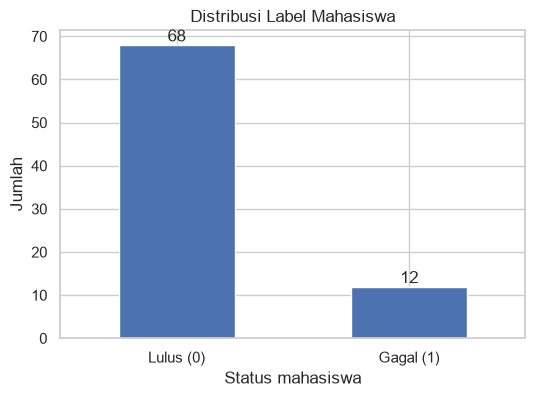

Persentase kelas:


,Persentase (%)
"label (fail=1, pass=0)",
Lulus (0),85.0
Gagal (1),15.0


Interpretasi: kelas tidak seimbang karena jumlah mahasiswa lulus jauh lebih banyak daripada mahasiswa gagal.


In [6]:
df = df.dropna(subset=[target_col]).copy()
df[target_col] = df[target_col].astype(int)

print("Dimensi setelah pembersihan awal:", df.shape)
print("Jumlah duplikat:", df.duplicated().sum())
print("\\nDistribusi label:")
display(df[target_col].value_counts().rename(index={0: "Lulus (0)", 1: "Gagal (1)"}).to_frame("Jumlah"))

label_pct = df[target_col].value_counts(normalize=True).sort_index() * 100
plt.figure(figsize=(6, 4))
counts = df[target_col].map({0: "Lulus (0)", 1: "Gagal (1)"}).value_counts().reindex(["Lulus (0)", "Gagal (1)"], fill_value=0)
ax = counts.plot(kind="bar", rot=0)
ax.set_title("Distribusi Label Mahasiswa")
ax.set_xlabel("Status mahasiswa")
ax.set_ylabel("Jumlah")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.show()

print("Persentase kelas:")
display(label_pct.rename(index={0: "Lulus (0)", 1: "Gagal (1)"}).to_frame("Persentase (%)"))
print("Interpretasi: kelas tidak seimbang karena jumlah mahasiswa lulus jauh lebih banyak daripada mahasiswa gagal.")

# Eda

In [8]:
print("Dimensi data:", df.shape)
print("Jumlah baris duplikat:", df.duplicated().sum())
print("Missing value per kolom:")
display(df.isna().sum().to_frame("Missing"))


Dimensi data: (80, 20)
Jumlah baris duplikat: 0
Missing value per kolom:


,Missing
Gender,0
Age,0
POLAR4 Quintile,0
POLAR3 Quintile,0
Adult HE 2001 Quintile,0
Adult HE 2011 Quintile,0
TUNDRA MSOA Quintile,0
TUNDRA LSOA Quintile,0
Gaps GCSE Quintile,0
Gaps GCSE Ethnicity Quintile,0


In [9]:
df = df.drop_duplicates().copy()

In [10]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
feature_cols_all = [c for c in numeric_cols if c != target_col]


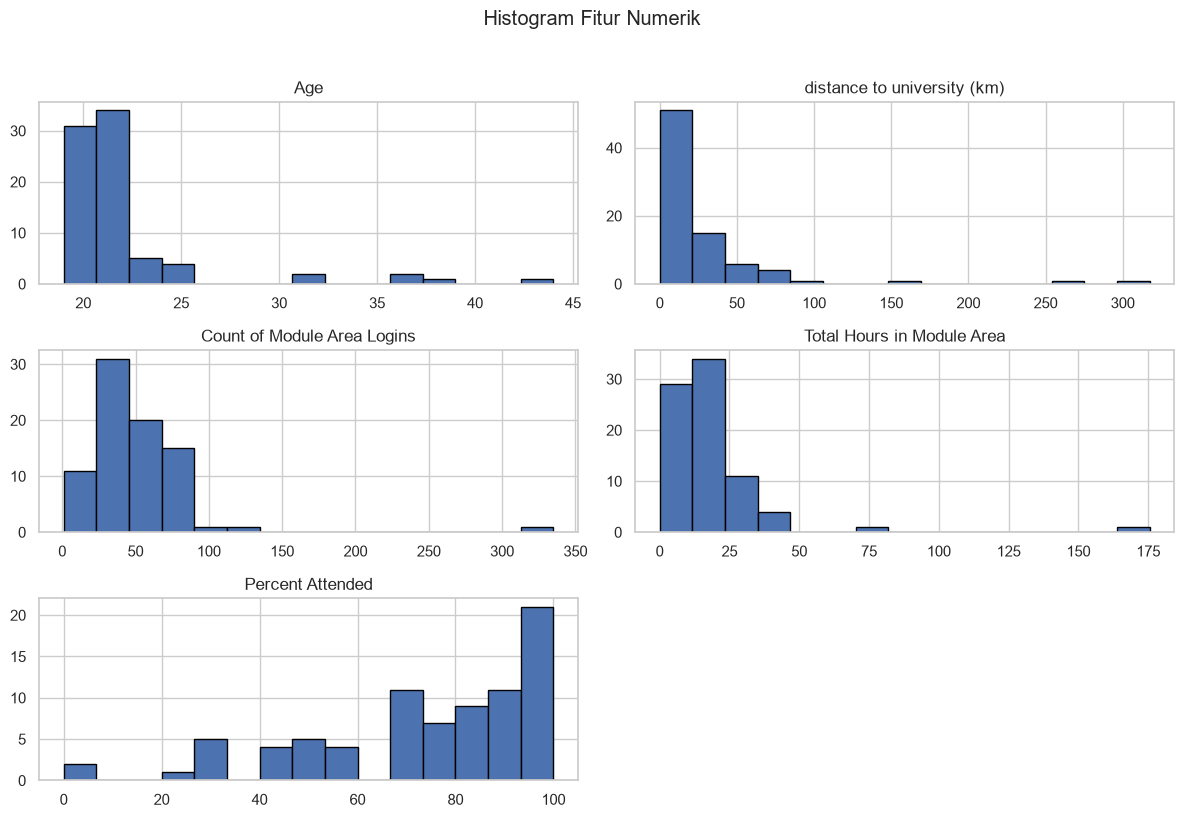

In [11]:
hist_cols = [
    "Age", "distance to university (km)", "Count of Module Area Logins",
    "Total Hours in Module Area", "Percent Attended"
]
hist_cols = [c for c in hist_cols if c in df.columns]
df[hist_cols].hist(figsize=(12, 8), bins=15, edgecolor="black")
plt.suptitle("Histogram Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()

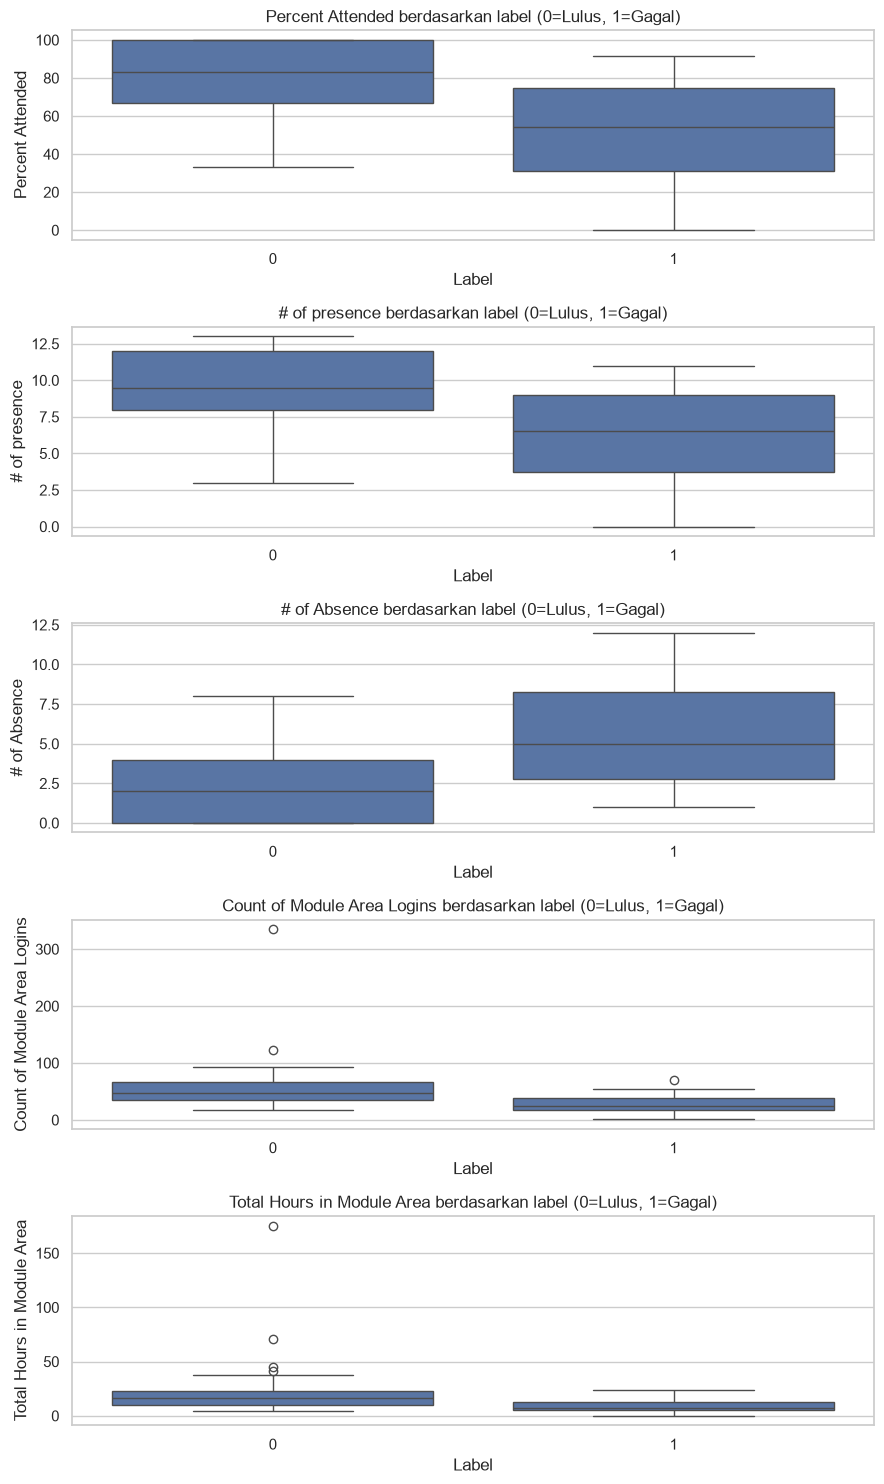

In [12]:
box_cols = [
    "Percent Attended", "# of presence", "# of Absence",
    "Count of Module Area Logins", "Total Hours in Module Area"
]
box_cols = [c for c in box_cols if c in df.columns]

fig, axes = plt.subplots(len(box_cols), 1, figsize=(9, 3 * len(box_cols)))
if len(box_cols) == 1:
    axes = [axes]
for ax, col in zip(axes, box_cols):
    sns.boxplot(data=df, x=target_col, y=col, ax=ax)
    ax.set_title(f"{col} berdasarkan label (0=Lulus, 1=Gagal)")
    ax.set_xlabel("Label")
plt.tight_layout()
plt.show()

"label (fail=1, pass=0)",Lulus (0),Gagal (1)
Percent Attended,78.553971,50.694444
# of presence,9.161765,6.083333
# of Absence,2.424242,5.750000
Count of Module Area Logins,54.014706,28.416667
Total Hours in Module Area,20.320588,9.023333
% of Average Hours in Module Area,1.186948,0.432312


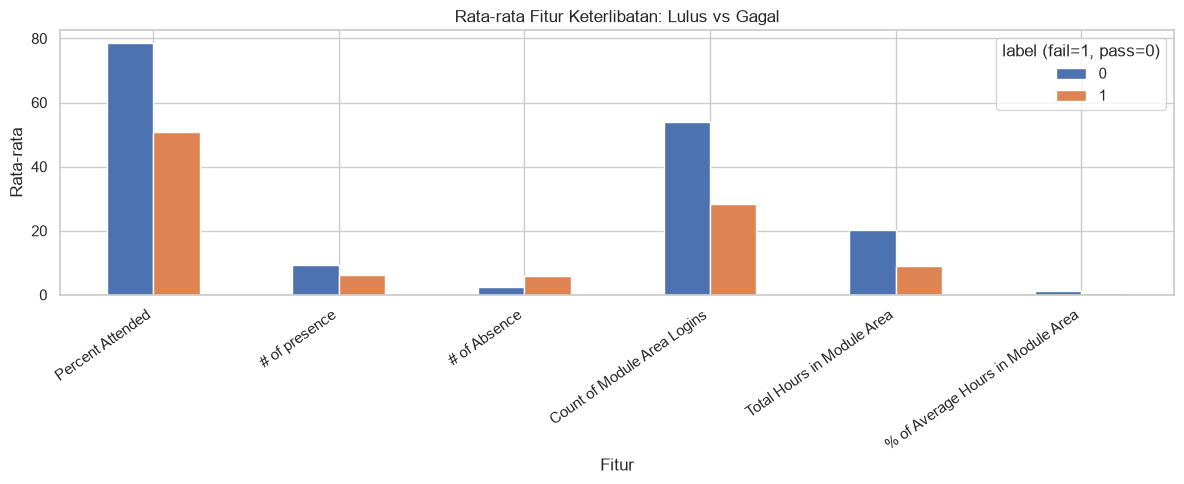

In [13]:
engagement_cols = [
    "Percent Attended", "# of presence", "# of Absence",
    "Count of Module Area Logins", "Total Hours in Module Area",
    "% of Average Hours in Module Area"
]
engagement_cols = [c for c in engagement_cols if c in df.columns]
mean_by_label = df.groupby(target_col)[engagement_cols].mean().T
display(mean_by_label.rename(columns={0: "Lulus (0)", 1: "Gagal (1)"}))

mean_by_label.plot(kind="bar", figsize=(12, 5))
plt.title("Rata-rata Fitur Keterlibatan: Lulus vs Gagal")
plt.ylabel("Rata-rata")
plt.xlabel("Fitur")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

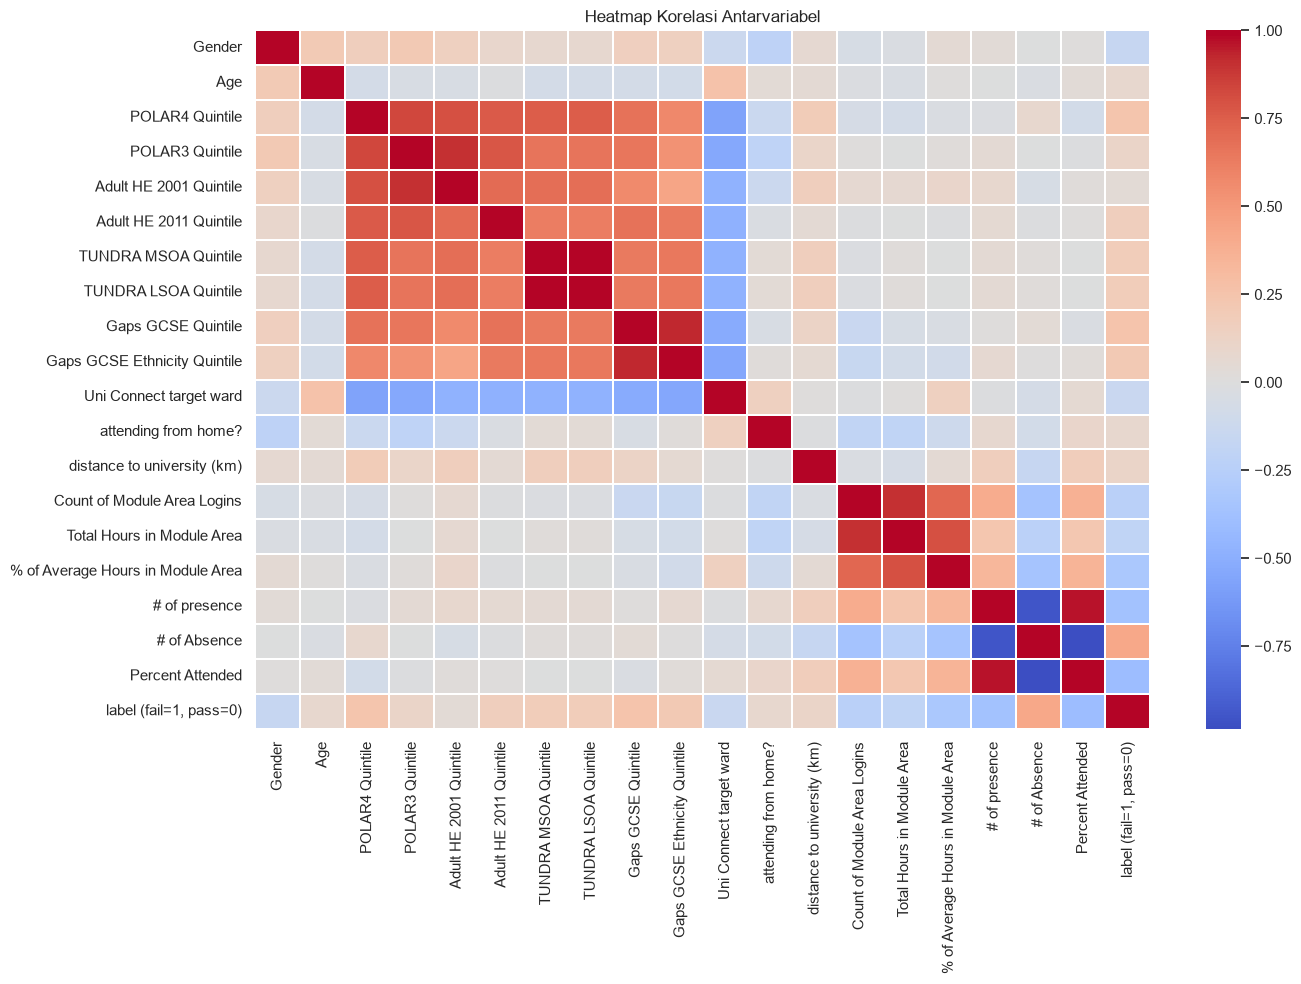

In [14]:
plt.figure(figsize=(14, 10))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=0.3)
plt.title("Heatmap Korelasi Antarvariabel")
plt.tight_layout()
plt.show()

In [15]:
continuous_cols = [
    "Age", "distance to university (km)", "Count of Module Area Logins",
    "Total Hours in Module Area", "% of Average Hours in Module Area",
    "# of presence", "# of Absence", "Percent Attended"
]
continuous_cols = [c for c in continuous_cols if c in df.columns]

outlier_summary = []
for col in continuous_cols:
    series = df[col].dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((series < lower) | (series > upper)).sum()
    outlier_summary.append([col, lower, upper, int(count)])

outlier_df = pd.DataFrame(outlier_summary, columns=["Fitur", "Batas bawah IQR", "Batas atas IQR", "Jumlah outlier"])
display(outlier_df)


,Fitur,Batas bawah IQR,Batas atas IQR,Jumlah outlier
0,Age,17.000000,25.000000,6
1,distance to university (km),-40.529151,76.240647,7
2,Count of Module Area Logins,-16.125000,108.875000,2
3,Total Hours in Module Area,-11.981250,42.768750,3
4,% of Average Hours in Module Area,-0.474730,2.343004,4
5,# of presence,1.000000,17.000000,2
6,# of Absence,-6.500000,11.500000,2
7,Percent Attended,-4.166667,162.500000,0


In [16]:
quintile_cols = [c for c in df.columns if "Quintile" in c]
zero_quintiles = {c: int((df[c] == 0).sum()) for c in quintile_cols}
print("Jumlah nilai 0 pada fitur kuintil:")
display(pd.Series(zero_quintiles, name="Jumlah nilai 0").to_frame())

print("Keputusan: nilai outlier numerik dipertahankan karena belum terbukti salah.")
print("Nilai 0 pada kolom kuintil diperlakukan sebagai nilai tidak tersedia (NaN), karena dokumen tugas menyatakan maknanya tidak dijelaskan dan mungkin menandakan data tidak tersedia.")

Jumlah nilai 0 pada fitur kuintil:


,Jumlah nilai 0
POLAR4 Quintile,0
POLAR3 Quintile,0
Adult HE 2001 Quintile,0
Adult HE 2011 Quintile,2
TUNDRA MSOA Quintile,2
TUNDRA LSOA Quintile,2
Gaps GCSE Quintile,4
Gaps GCSE Ethnicity Quintile,4


Keputusan: nilai outlier numerik dipertahankan karena belum terbukti salah.
Nilai 0 pada kolom kuintil diperlakukan sebagai nilai tidak tersedia (NaN), karena dokumen tugas menyatakan maknanya tidak dijelaskan dan mungkin menandakan data tidak tersedia.


# Persipan Data

In [17]:
model_df = df.copy()


In [18]:
quintile_cols = [c for c in model_df.columns if "Quintile" in c]
for col in quintile_cols:
    model_df.loc[model_df[col] == 0, col] = np.nan


In [19]:
redundant_cols = ["TUNDRA LSOA Quintile", "Percent Attended"]
drop_cols = [c for c in redundant_cols if c in model_df.columns]
model_df = model_df.drop(columns=drop_cols)

X = model_df.drop(columns=[target_col])
y = model_df[target_col].astype(int)

In [20]:
X = X.apply(pd.to_numeric, errors="coerce")

print("Fitur yang digunakan:", X.columns.tolist())
print("Jumlah fitur:", X.shape[1])
print("Ukuran X:", X.shape, "| Ukuran y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("\\nDistribusi label data latih:")
display(y_train.value_counts().rename(index={0: "Lulus", 1: "Gagal"}).to_frame("Jumlah"))
print("\\nDistribusi label data uji:")
display(y_test.value_counts().rename(index={0: "Lulus", 1: "Gagal"}).to_frame("Jumlah"))

Fitur yang digunakan: ['Gender', 'Age', 'POLAR4 Quintile', 'POLAR3 Quintile', 'Adult HE 2001 Quintile', 'Adult HE 2011 Quintile', 'TUNDRA MSOA Quintile', 'Gaps GCSE Quintile', 'Gaps GCSE Ethnicity Quintile', 'Uni Connect target ward', 'attending from home?', 'distance to university (km)', 'Count of Module Area Logins', 'Total Hours in Module Area', '% of Average Hours in Module Area', '# of presence', '# of Absence']
Jumlah fitur: 17
Ukuran X: (80, 17) | Ukuran y: (80,)
Data latih: (64, 17) | Data uji: (16, 17)
\nDistribusi label data latih:


,Jumlah
"label (fail=1, pass=0)",
Lulus,54
Gagal,10


\nDistribusi label data uji:


,Jumlah
"label (fail=1, pass=0)",
Lulus,14
Gagal,2


# Modelling

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, max_depth=3))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced",
            random_state=RANDOM_STATE, max_depth=4, min_samples_leaf=2
        ))
    ])
}

cv_rows = []
for name, pipeline in models.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv,
        scoring={"f1": "f1", "recall": "recall", "precision": "precision", "accuracy": "accuracy"},
        error_score="raise"
    )
    cv_rows.append({
        "Model": name,
        "CV F1 gagal (rata-rata)": scores["test_f1"].mean(),
        "CV Recall gagal (rata-rata)": scores["test_recall"].mean(),
        "CV Precision gagal (rata-rata)": scores["test_precision"].mean(),
        "CV Accuracy (rata-rata)": scores["test_accuracy"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV F1 gagal (rata-rata)", ascending=False)
display(cv_results)


,Model,CV F1 gagal (rata-rata),CV Recall gagal (rata-rata),CV Precision gagal (rata-rata),CV Accuracy (rata-rata)
0,Logistic Regression,0.493333,0.6,0.483333,0.798718
1,Decision Tree,0.413333,0.5,0.416667,0.798718
2,Random Forest,0.360000,0.4,0.383333,0.767949


In [22]:
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE))
])

param_grid = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 3, 5],
    "model__min_samples_leaf": [1, 2, 3]
}

grid_search = GridSearchCV(
    rf_pipeline, param_grid=param_grid, scoring="f1",
    cv=cv, n_jobs=-1, refit=True
)
grid_search.fit(X_train, y_train)

print("Parameter terbaik:", grid_search.best_params_)
print("F1 CV terbaik untuk kelas gagal:", round(grid_search.best_score_, 4))

Parameter terbaik: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
F1 CV terbaik untuk kelas gagal: 0.4133


In [23]:
fitted_models = {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline
fitted_models["Random Forest Tuned"] = grid_search.best_estimator_

print("Semua model berhasil dilatih.")

Semua model berhasil dilatih.


# Evaluasi

In [24]:
evaluation_rows = []
for name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision gagal": precision_score(y_test, y_pred, zero_division=0),
        "Recall gagal": recall_score(y_test, y_pred, zero_division=0),
        "F1 gagal": f1_score(y_test, y_pred, zero_division=0)
    })

evaluation = pd.DataFrame(evaluation_rows).sort_values("F1 gagal", ascending=False).reset_index(drop=True)
display(evaluation)

best_model_name = evaluation.loc[0, "Model"]
best_model = fitted_models[best_model_name]
print("Model terbaik berdasarkan F1 kelas gagal pada data uji:", best_model_name)

,Model,Accuracy,Precision gagal,Recall gagal,F1 gagal
0,Random Forest Tuned,0.9375,1.00,0.5,0.666667
1,Random Forest,0.9375,1.00,0.5,0.666667
2,Logistic Regression,0.7500,0.25,0.5,0.333333
3,Decision Tree,0.8125,0.00,0.0,0.000000


Model terbaik berdasarkan F1 kelas gagal pada data uji: Random Forest Tuned


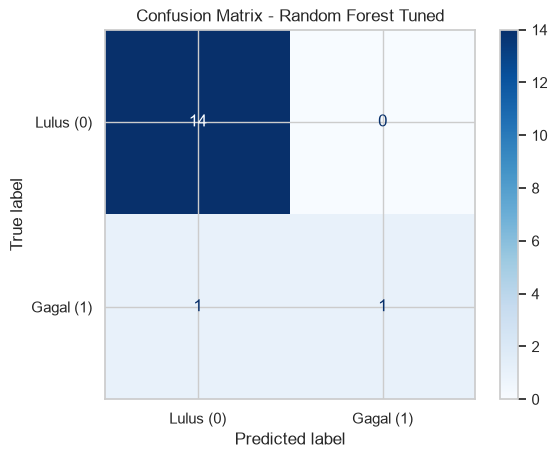

Classification Report:
              precision    recall  f1-score   support

   Lulus (0)       0.93      1.00      0.97        14
   Gagal (1)       1.00      0.50      0.67         2

    accuracy                           0.94        16
   macro avg       0.97      0.75      0.82        16
weighted avg       0.94      0.94      0.93        16



In [25]:
best_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, best_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Lulus (0)", "Gagal (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

print("Classification Report:")
print(classification_report(
    y_test, best_pred, labels=[0, 1],
    target_names=["Lulus (0)", "Gagal (1)"],
    zero_division=0
))

Feature Importance


,Nilai
% of Average Hours in Module Area,0.258540
Count of Module Area Logins,0.136323
Total Hours in Module Area,0.130199
# of Absence,0.082942
# of presence,0.065965
distance to university (km),0.062835
POLAR4 Quintile,0.049676
Adult HE 2011 Quintile,0.037699
Age,0.037104
POLAR3 Quintile,0.035377


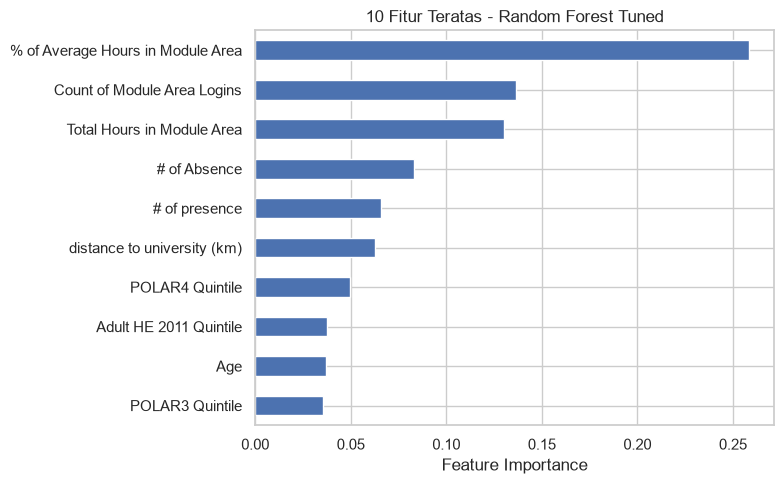

In [26]:
final_estimator = best_model.named_steps["model"]

if hasattr(final_estimator, "feature_importances_"):
    importance = pd.Series(final_estimator.feature_importances_, index=X.columns).sort_values(ascending=False)
    importance_name = "Feature Importance"
elif hasattr(final_estimator, "coef_"):
    importance = pd.Series(np.abs(final_estimator.coef_[0]), index=X.columns).sort_values(ascending=False)
    importance_name = "Nilai absolut koefisien Logistic Regression"
else:
    importance = pd.Series(dtype=float)
    importance_name = "Tidak tersedia"

if not importance.empty:
    print(importance_name)
    display(importance.to_frame("Nilai").head(10))
    importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
    plt.title(f"10 Fitur Teratas - {best_model_name}")
    plt.xlabel(importance_name)
    plt.tight_layout()
    plt.show()
else:
    print("Model ini tidak menyediakan feature importance atau koefisien.")

In [27]:
rng = np.random.default_rng(RANDOM_STATE)
random_students = {}


In [28]:
discrete_cols = [
    "Gender", "POLAR4 Quintile", "POLAR3 Quintile",
    "Adult HE 2001 Quintile", "Adult HE 2011 Quintile",
    "TUNDRA MSOA Quintile", "Gaps GCSE Quintile",
    "Gaps GCSE Ethnicity Quintile", "Uni Connect target ward",
    "attending from home?"
]
discrete_cols = [c for c in discrete_cols if c in X.columns]

for col in X.columns:
    values = X[col].dropna()
    if values.empty:
        random_students[col] = np.zeros(5)
    elif col in discrete_cols:
        choices = values.unique()
        random_students[col] = rng.choice(choices, size=5, replace=True)
    else:
        low, high = values.min(), values.max()
        random_students[col] = rng.uniform(low, high, size=5)

new_students = pd.DataFrame(random_students, columns=X.columns)
display(new_students.round(2))

,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence
0,0.0,36.43,2.0,4.0,2.0,4.0,4.0,5.0,2.0,1.0,1.0,236.33,64.28,76.71,4.43,2.60,9.37
1,1.0,21.35,3.0,2.0,3.0,3.0,5.0,1.0,1.0,0.0,0.0,307.02,44.39,146.09,2.13,0.10,5.51
2,1.0,43.39,5.0,5.0,5.0,5.0,5.0,1.0,2.0,0.0,1.0,103.39,159.89,122.86,1.59,10.23,6.82
3,0.0,38.03,2.0,1.0,3.0,4.0,3.0,4.0,3.0,0.0,0.0,117.56,76.79,54.82,3.76,8.64,1.68
4,0.0,38.65,3.0,3.0,3.0,2.0,1.0,5.0,3.0,0.0,0.0,149.00,224.72,146.02,0.77,9.17,1.37


In [29]:
new_predictions = best_model.predict(new_students)
new_probabilities = best_model.predict_proba(new_students)

In [30]:
class_order = list(best_model.classes_)
fail_index = class_order.index(1)
fail_probability = new_probabilities[:, fail_index]

prediction_result = new_students.copy()
prediction_result["Prediksi label"] = new_predictions
prediction_result["Prediksi status"] = np.where(new_predictions == 1, "GAGAL", "LULUS")
prediction_result["Probabilitas gagal (%)"] = (fail_probability * 100).round(2)
prediction_result["Probabilitas lulus (%)"] = ((1 - fail_probability) * 100).round(2)

display(prediction_result.round(2))


,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Prediksi label,Prediksi status,Probabilitas gagal (%),Probabilitas lulus (%)
0,0.0,36.43,2.0,4.0,2.0,4.0,4.0,5.0,2.0,1.0,1.0,236.33,64.28,76.71,4.43,2.60,9.37,0,LULUS,12.0,88.0
1,1.0,21.35,3.0,2.0,3.0,3.0,5.0,1.0,1.0,0.0,0.0,307.02,44.39,146.09,2.13,0.10,5.51,0,LULUS,12.0,88.0
2,1.0,43.39,5.0,5.0,5.0,5.0,5.0,1.0,2.0,0.0,1.0,103.39,159.89,122.86,1.59,10.23,6.82,0,LULUS,16.0,84.0
3,0.0,38.03,2.0,1.0,3.0,4.0,3.0,4.0,3.0,0.0,0.0,117.56,76.79,54.82,3.76,8.64,1.68,0,LULUS,6.0,94.0
4,0.0,38.65,3.0,3.0,3.0,2.0,1.0,5.0,3.0,0.0,0.0,149.00,224.72,146.02,0.77,9.17,1.37,0,LULUS,13.5,86.5
